# 1. DAILY BBMR MEAN REVERSION — HYPOTHESIS DEFINITION & BASELINE BACKTEST

## 1.1 CORE QUANTITATIVE HYPOTHESIS
The strategy exploits three structural properties of equity index markets:
- **Macro Trend Drift**: persistent multi-decade upward drift.
- **Short-Term Micro Reversal**: negative daily autocorrelation; sub-diffusive Hurst.
- **Regime Dependence**: mean-reversion edges work in ranges (ADX < 25) and break in trends (ADX > 30).

When an asset in a macro bull market (`Close > SMA(200)`) is in a range regime (`ADX(14) < 25`),
a touch of the lower Bollinger Band (`Low <= BB_lower(20, 2σ)`) accompanied by a rejection bar
(`(Close - Low)/(High - Low) >= 0.5`) signals exhaustion. The bounce toward the middle band
generates an asymmetric, high-probability edge over 5–15 sessions, bounded by a hard ATR stop.

## 1.2 FROZEN STRATEGY RULES
| Component | Specification |
|---|---|
| Instrument | Daily bars (split/dividend adjusted), Yahoo or broker CSV |
| Trend Filter | `Close[t-1] > SMA(sma_len)[t-1]` |
| Regime Filter | `ADX(14)[t-1] < adx_thr` |
| Entry Trigger | `Low[t-1] <= BB_lower[t-1]` AND `rejection[t-1] >= rejection_ratio` |
| Execution | Buy at **OPEN** of day t with slippage: `Entry = Open[t] * (1 + slip)` |
| Hard Stop | `Entry_price - atr_stop_mult * ATR(14)[t-1]`, checked intrabar |
| Target | Exit when `Close[t-1] >= BB_mid[t-1]` at `Open[t]` |
| Time Stop | Exit after `max_bars` bars held |
| Direction | Long only |
| Costs | `slip_bps_per_side` per side + `financing_bps_per_night` for CFDs |
| Sizing | (a) Capital 100%<br>(b) ATR `risk_per_trade_pct` with `atr_stop_mult × ATR` |

## 1.3 PROVENANCE & ADAPTATION
- Bollinger Bands (J. Bollinger, 1980s).
- ADX (J. Welles Wilder, *New Concepts in Technical Trading Systems*, 1978).
- Mean reversion + trend filter: Connors & Alvarez (*Short Term Trading Strategies That Work*, 2008).
- **Alphaca Refinement**: added the ADX regime filter and the rejection-bar requirement,
  and converted the virtual ATR stop into a **real** intrabar stop — materially less
  capital-hungry than the original RSI(2) while preserving the thesis.

In [3]:
VARIANT    = "v1_us500"
STOP_LIMIT = 0.09
ATR_STOP   = 2.0

## 2. IMPORTS AND CONFIG

In [4]:
%pip install pandas_market_calendars plotly -q

import os, sys, json, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D
from numpy.lib.stride_tricks import sliding_window_view

def find_upwards(name, start=None, must_be_dir=True):
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        target = base / name
        if target.is_dir() if must_be_dir else target.exists():
            return base
    raise FileNotFoundError(f"Could not find '{name}' walking up from {here}")

EDGE_DIR    = find_upwards('variants')
utils_path  = str(find_upwards('utils') / 'utils')
engine_path = str(EDGE_DIR)
engine_dir  = str(EDGE_DIR / 'bbmr_engine')
for p in (utils_path, engine_path, engine_dir):
    if p not in sys.path:
        sys.path.insert(0, p)

from utils import compute_metrics, plot_equity_curve
from metrics import sharpe_ratio, max_drawdown
import bbmr_engine as eng
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng)
variant_config.EDGE_DIR = EDGE_DIR
assert (variant_config.EDGE_DIR / "variants").is_dir(), \
    f"Doesn't exist {variant_config.EDGE_DIR / 'variants'}"

cfg         = load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
RUN_DIR     = cfg["run_dir"]
TICKER      = cfg["instrument"]["ticker"]
DATA_START  = cfg["instrument"]["start"]
OOS_START   = cfg["oos_start_ts"]

BB_LEN          = cfg["params"]["bb_len"]
BB_STD          = cfg["params"]["bb_std"]
ADX_THR         = cfg["params"]["adx_thr"]
SMA_LEN         = cfg["params"]["sma_len"]
REJECTION_RATIO = cfg["params"]["rejection_ratio"]
MAX_BARS        = cfg["params"]["max_bars"]
ATR_STOP_MULT   = cfg["params"]["atr_stop_mult"]
SLIP_BPS        = cfg["params"]["slip_bps_per_side"]
SLIP            = SLIP_BPS / 10_000

print("Imports complete.")
print(f"Loaded bbmr_engine from: {eng.__file__}")
print(f"Variant: {cfg['id']} | {TICKER}")
print(f"  BB({BB_LEN},{BB_STD})  ADX<{ADX_THR}  SMA({SMA_LEN})  reject>={REJECTION_RATIO}  max_bars={MAX_BARS}")
print(f"  ATR stop: {ATR_STOP_MULT}x  |  slip {SLIP_BPS:g} bps/side")
print(f"Data source: {eng.ENGINE_DEFAULTS['data_source']} | swap: {eng.ENGINE_DEFAULTS['financing_bps_per_night']:g} bps/night")


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Imports complete.
Loaded bbmr_engine from: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/notebooks/BBMR/bbmr_engine.py
Variant: BBMR.us500.m30 | us500
  BB(20,2.0)  ADX<25.0  SMA(200)  reject>=0.5  max_bars=15
  ATR stop: 2.0x  |  slip 5 bps/side
Data source: csv_intraday | swap: 2 bps/night


## 3. LOAD DATA AND IN-SAMPLE / OUT-OF-SAMPLE SPLIT

In [5]:
df_raw = eng.load_data(TICKER, start=DATA_START)
print(len(df_raw), df_raw.index.dayofweek.value_counts().sort_index().to_dict())

df = eng.prepare(df_raw, sma_len=SMA_LEN, bb_len=BB_LEN, bb_std=BB_STD)

n_is = int((df.index < OOS_START).sum())
df_is  = df.iloc[:n_is].copy()
df_oos = df.iloc[n_is:].copy()
assert len(df_is) > 0 and len(df_oos) > 0, "Check split.oos_start against the history of this ticker."
oos_start = df_oos.index[0]

print("=" * 70)
print("DATA INGESTION & DATASET SPLIT")
print("=" * 70)
print(f"Total Prepared Bars : {len(df):,} ({df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d})")
print(f"In-Sample           : {len(df_is):,} ({df_is.index.min():%Y-%m-%d} to {df_is.index.max():%Y-%m-%d})")
print(f"Out-of-Sample       : {len(df_oos):,} ({df_oos.index.min():%Y-%m-%d} to {df_oos.index.max():%Y-%m-%d})")
print("=" * 70)
df.head()

3464 {0: 648, 1: 714, 2: 711, 3: 697, 4: 694}
DATA INGESTION & DATASET SPLIT
Total Prepared Bars : 3,265 (2013-10-22 to 2026-10-16)
In-Sample           : 1,238 (2013-10-22 to 2018-09-21)
Out-of-Sample       : 2,027 (2018-09-24 to 2026-10-16)


,open,high,low,close,volume,sma,bb_mid,bb_upper,bb_lower,adx,atr14,rejection
time,,,,,,,,,,,,
2013-10-22,1742.498,1759.322,1742.498,1757.081,1.169100,1608.148030,1698.62100,1750.447659,1646.794341,19.132941,16.591758,0.866797
2013-10-23,1751.952,1751.952,1741.802,1744.361,0.916000,1609.587635,1700.97075,1756.486800,1645.454700,20.540979,16.497989,0.252118
2013-10-25,1756.100,1760.600,1752.600,1760.400,0.000000,1611.106135,1704.34585,1765.417938,1643.273762,22.157003,16.479490,0.975000
2013-10-28,1759.471,1765.181,1757.494,1762.978,1.112669,1612.583325,1707.55485,1773.660820,1641.448880,23.814850,15.851455,0.713412
2013-10-29,1766.470,1771.876,1764.466,1771.876,4.700877,1614.137855,1711.71365,1782.827346,1640.599954,25.578519,15.354780,1.000000


## 4. BASELINE BACKTEST WITH FROZEN RULES

PERFORMANCE SUMMARY (NET OF 5 BPS SLIPPAGE PER SIDE)


,Period,Sizing,Trades,Win Rate,Profit Factor,Expectancy,Total Return,Sharpe,Max Drawdown
0,In-Sample (2013-2018),100% Capital,27,74.1%,1.685,0.288%,9.0%,0.49,-4.63%
1,In-Sample (2013-2018),1% ATR Risk,27,74.1%,1.850,0.176%,5.5%,0.58,-2.68%
2,Out-of-Sample (2018-2026),100% Capital,29,58.6%,1.041,0.041%,3.7%,0.12,-13.77%
3,Out-of-Sample (2018-2026),1% ATR Risk,29,58.6%,0.935,-0.028%,0.1%,0.02,-6.37%
4,Full Period (2013-2026),100% Capital,56,66.1%,1.222,0.160%,13.0%,0.25,-13.77%
5,Full Period (2013-2026),1% ATR Risk,56,66.1%,1.221,0.071%,5.7%,0.24,-6.37%


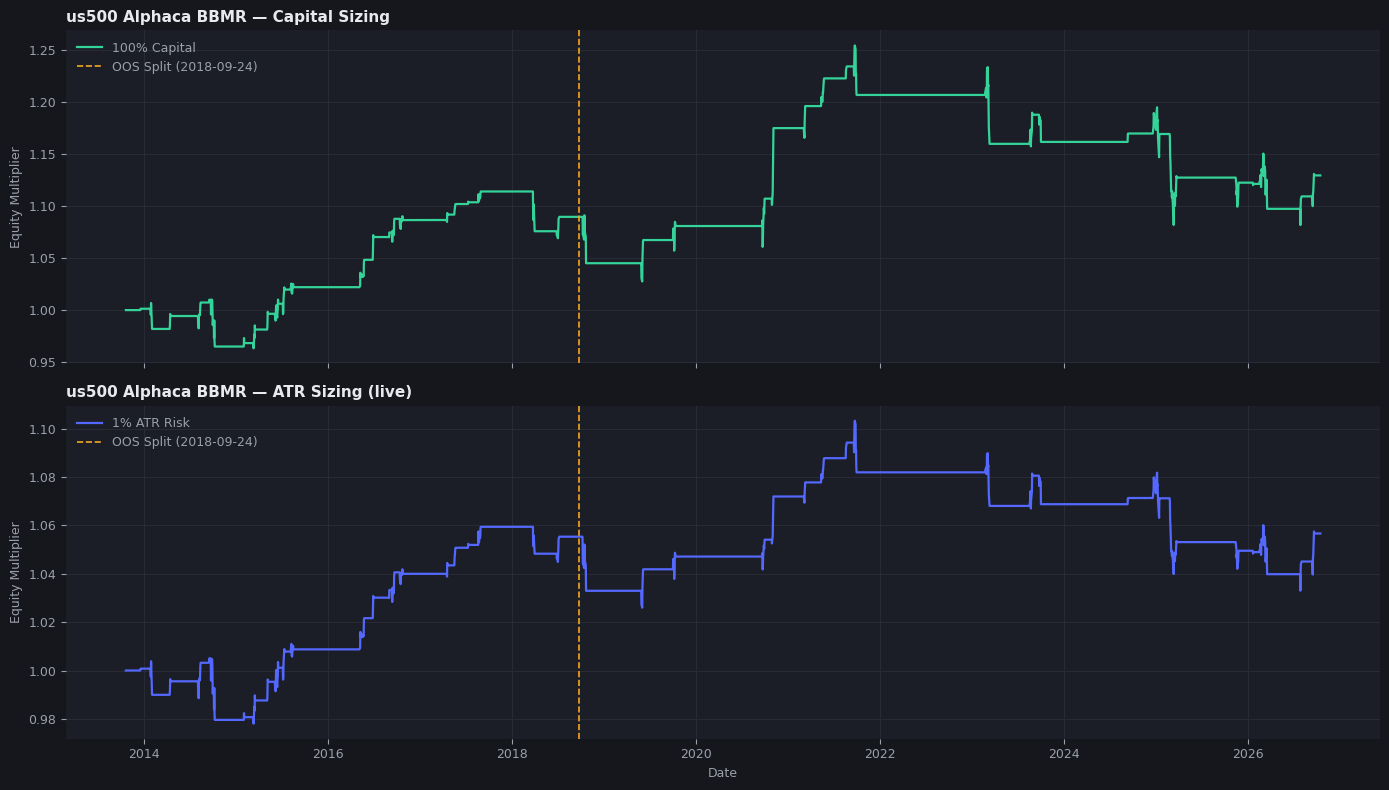

In [6]:
def _bbmr_kwargs(**over):
    kw = dict(
        bb_len=BB_LEN, bb_std=BB_STD, adx_thr=ADX_THR, sma_len=SMA_LEN,
        rejection_ratio=REJECTION_RATIO, max_bars=MAX_BARS,
        atr_stop_mult=ATR_STOP_MULT, slip_bps_per_side=SLIP_BPS,
    )
    kw.update(over)
    return kw

trades_is  = eng.run_bbmr_backtest(df_is,  **_bbmr_kwargs())
trades_oos = eng.run_bbmr_backtest(df_oos, **_bbmr_kwargs())
trades_all = eng.run_bbmr_backtest(df,     **_bbmr_kwargs())

def format_perf_table(t_df, period_name, price_df):
    m_cap = compute_metrics(t_df, contract_multiplier=1.0, cost_per_trade=0.0)
    t_atr = t_df.assign(pnl=t_df['pnl_atr'], win=t_df['pnl_atr'] > 0)
    m_atr = compute_metrics(t_atr, contract_multiplier=1.0, cost_per_trade=0.0)

    ret_cap = eng.daily_returns(price_df, t_df, sizing="capital")
    ret_atr = eng.daily_returns(price_df, t_df, sizing="atr")
    eq_cap = (1.0 + ret_cap).cumprod()
    eq_atr = (1.0 + ret_atr).cumprod()

    return pd.DataFrame([
        {'Period': period_name, 'Sizing': '100% Capital',
         'Trades': m_cap['num_trades'], 'Win Rate': f"{m_cap['win_rate']:.1f}%",
         'Profit Factor': f"{m_cap['profit_factor']:.3f}",
         'Expectancy': f"{m_cap['expectancy']:.3f}%",
         'Total Return': f"{(eq_cap.iloc[-1] - 1)*100:.1f}%",
         'Sharpe': f"{sharpe_ratio(ret_cap):.2f}",
         'Max Drawdown': f"{max_drawdown(eq_cap)*100:.2f}%"},
        {'Period': period_name, 'Sizing': '1% ATR Risk',
         'Trades': m_atr['num_trades'], 'Win Rate': f"{m_atr['win_rate']:.1f}%",
         'Profit Factor': f"{m_atr['profit_factor']:.3f}",
         'Expectancy': f"{m_atr['expectancy']:.3f}%",
         'Total Return': f"{(eq_atr.iloc[-1] - 1)*100:.1f}%",
         'Sharpe': f"{sharpe_ratio(ret_atr):.2f}",
         'Max Drawdown': f"{max_drawdown(eq_atr)*100:.2f}%"},
    ])

perf_table = pd.concat([
    format_perf_table(trades_is,  f"In-Sample ({df_is.index[0].year}-{df_is.index[-1].year})", df_is),
    format_perf_table(trades_oos, f"Out-of-Sample ({df_oos.index[0].year}-{df_oos.index[-1].year})", df_oos),
    format_perf_table(trades_all, f"Full Period ({df.index[0].year}-{df.index[-1].year})", df),
], ignore_index=True)

print("=" * 80)
print(f"PERFORMANCE SUMMARY (NET OF {SLIP_BPS:g} BPS SLIPPAGE PER SIDE)")
print("=" * 80)
display(perf_table)

ret_cap_all = eng.daily_returns(df, trades_all, sizing="capital")
ret_atr_all = eng.daily_returns(df, trades_all, sizing="atr")
eq_cap_all  = (1.0 + ret_cap_all).cumprod()
eq_atr_all  = (1.0 + ret_atr_all).cumprod()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, facecolor='#15171c')
for ax in (ax1, ax2):
    ax.set_facecolor('#1b1e26'); ax.grid(True, color='#2a2d37', linewidth=0.8, alpha=0.9)
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(colors='#9aa0ab', labelsize=9)

split_label = f"OOS Split ({oos_start:%Y-%m-%d})"
ax1.plot(df.index, eq_cap_all, color='#34d399', lw=1.6, label='100% Capital')
ax1.axvline(oos_start, color='#f5a524', ls='--', lw=1.2, label=split_label)
ax1.set_title(f'{TICKER} Alphaca BBMR — Capital Sizing', color='#e8e9ec', fontweight='bold', fontsize=11, loc='left')
ax1.set_ylabel('Equity Multiplier', color='#9aa0ab', fontsize=9)
ax1.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9, loc='upper left')

ax2.plot(df.index, eq_atr_all, color='#5468ff', lw=1.6, label='1% ATR Risk')
ax2.axvline(oos_start, color='#f5a524', ls='--', lw=1.2, label=split_label)
ax2.set_title(f'{TICKER} Alphaca BBMR — ATR Sizing (live)', color='#e8e9ec', fontweight='bold', fontsize=11, loc='left')
ax2.set_ylabel('Equity Multiplier', color='#9aa0ab', fontsize=9)
ax2.set_xlabel('Date', color='#9aa0ab', fontsize=9)
ax2.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9, loc='upper left')
plt.tight_layout(); plt.show()

## 4.1 · ADX REGIME DISTRIBUTION

BBMR only has "permission" to trade when `ADX < adx_thr`. Visualizes regime eligibility
and the annual breakdown of "in-range" vs "in-trend" days.

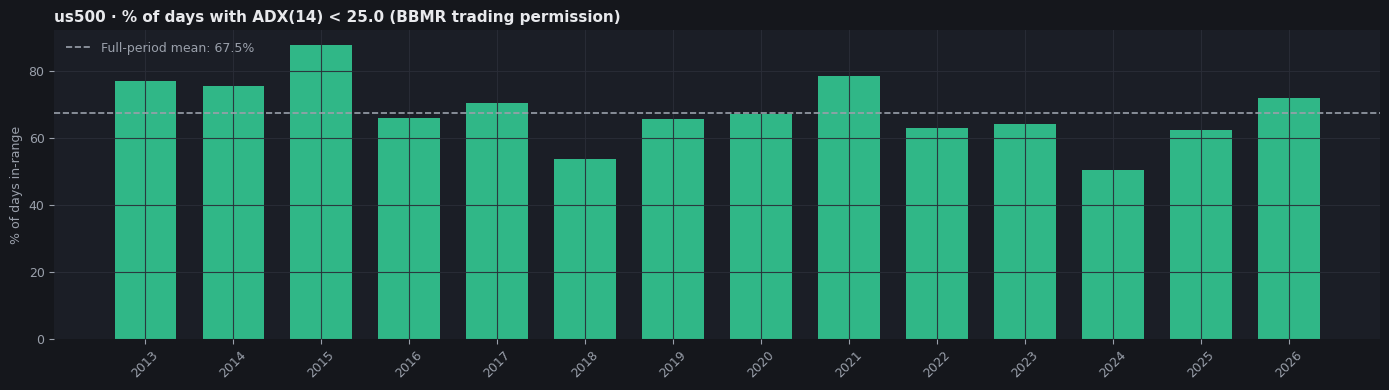

Full-period time in range: 67.5%
Days eligible (in-range AND above SMA): 58.9%


In [7]:
regime = (df['adx'] < ADX_THR)
regime_by_year = regime.groupby(regime.index.year).mean()

fig, ax = plt.subplots(figsize=(14, 4), facecolor='#15171c')
ax.set_facecolor('#1b1e26'); ax.grid(True, color='#2a2d37', linewidth=0.8, alpha=0.9)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(colors='#9aa0ab', labelsize=9)

ax.bar(regime_by_year.index, regime_by_year.values * 100,
       color=['#34d399' if v > 0.4 else '#f5a524' for v in regime_by_year.values],
       alpha=0.85, width=0.7)
ax.axhline(regime.mean() * 100, color='#9aa0ab', ls='--', lw=1.2,
           label=f"Full-period mean: {regime.mean()*100:.1f}%")
ax.set_title(f'{TICKER} · % of days with ADX(14) < {ADX_THR} (BBMR trading permission)',
             color='#e8e9ec', fontweight='bold', fontsize=11, loc='left')
ax.set_ylabel('% of days in-range', color='#9aa0ab', fontsize=9)
ax.set_xticks(regime_by_year.index)
ax.set_xticklabels(regime_by_year.index, rotation=45, color='#9aa0ab')
ax.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9, loc='upper left')
plt.tight_layout(); plt.show()

print(f"Full-period time in range: {regime.mean()*100:.1f}%")
print(f"Days eligible (in-range AND above SMA): {((df['adx']<ADX_THR) & (df['close']>df['sma'])).mean()*100:.1f}%")

## 4.2 · HARD STOP HIT RATE & GAP-THROUGH ANALYSIS

In [8]:
reason_counts = trades_all['reason'].value_counts().rename_axis("Exit reason").to_frame("Count")
reason_counts["%"] = (reason_counts["Count"] / len(trades_all) * 100).round(2)
print("=" * 70); print("EXIT REASON BREAKDOWN"); print("=" * 70)
display(reason_counts)

hard_stops = trades_all[trades_all['reason'] == 'hard_stop']
print(f"\nHard stops hit: {len(hard_stops)} / {len(trades_all)} trades ({len(hard_stops)/max(len(trades_all),1)*100:.1f}%)")

gap_throughs = hard_stops[hard_stops['exit_price'] < hard_stops['stop_price'] - 1e-6].copy()
print(f"Of which gap-through (opened below stop): {len(gap_throughs)} trades")
if len(gap_throughs) > 0:
    gap_slip = (gap_throughs['stop_price'] - gap_throughs['exit_price']) / gap_throughs['stop_price']
    print(f"Gap slip in excess of stop: mean {gap_slip.mean()*100:.2f}%, "
          f"p95 {gap_slip.quantile(0.95)*100:.2f}%, max {gap_slip.max()*100:.2f}%")

EXIT REASON BREAKDOWN


,Count,%
Exit reason,,
target,40,71.43
hard_stop,16,28.57



Hard stops hit: 16 / 56 trades (28.6%)
Of which gap-through (opened below stop): 16 trades
Gap slip in excess of stop: mean 0.25%, p95 0.81%, max 0.89%


## 4.5 · ANNUAL RETURNS

ANNUAL RETURNS | 2013-10-22 -> 2026-10-16


,ATR (live robot),100% Capital
CAGR (whole period),+0.43%,+0.94%
Mean annual (full years),+0.42%,+1.06%
Median annual (full years),+0.74%,+1.91%
Best year,2016 +3.10%,2020 +8.71%
Worst year,2018 -2.50%,2018 -6.19%
Positive years,7 / 12 (58%),7 / 12 (58%)
Years breaching the limit,0,-


,ATR return,ATR MaxDD,Capital return,Days,Note,Breaches limit
Year,,,,,,
2013,+0.08%,0.00%,+0.13%,48,partial year,
2014,-2.12%,-2.53%,-3.63%,252,,
2015,+2.98%,-0.73%,+5.92%,252,,
2016,+3.10%,-0.48%,+6.31%,252,,
2017,+1.87%,-0.42%,+2.53%,251,,
2018,-2.50%,-2.50%,-6.19%,251,,
2019,+1.37%,-0.79%,+3.42%,252,,
2020,+2.37%,-0.64%,+8.71%,253,,
2021,+0.93%,-1.93%,+2.71%,252,,


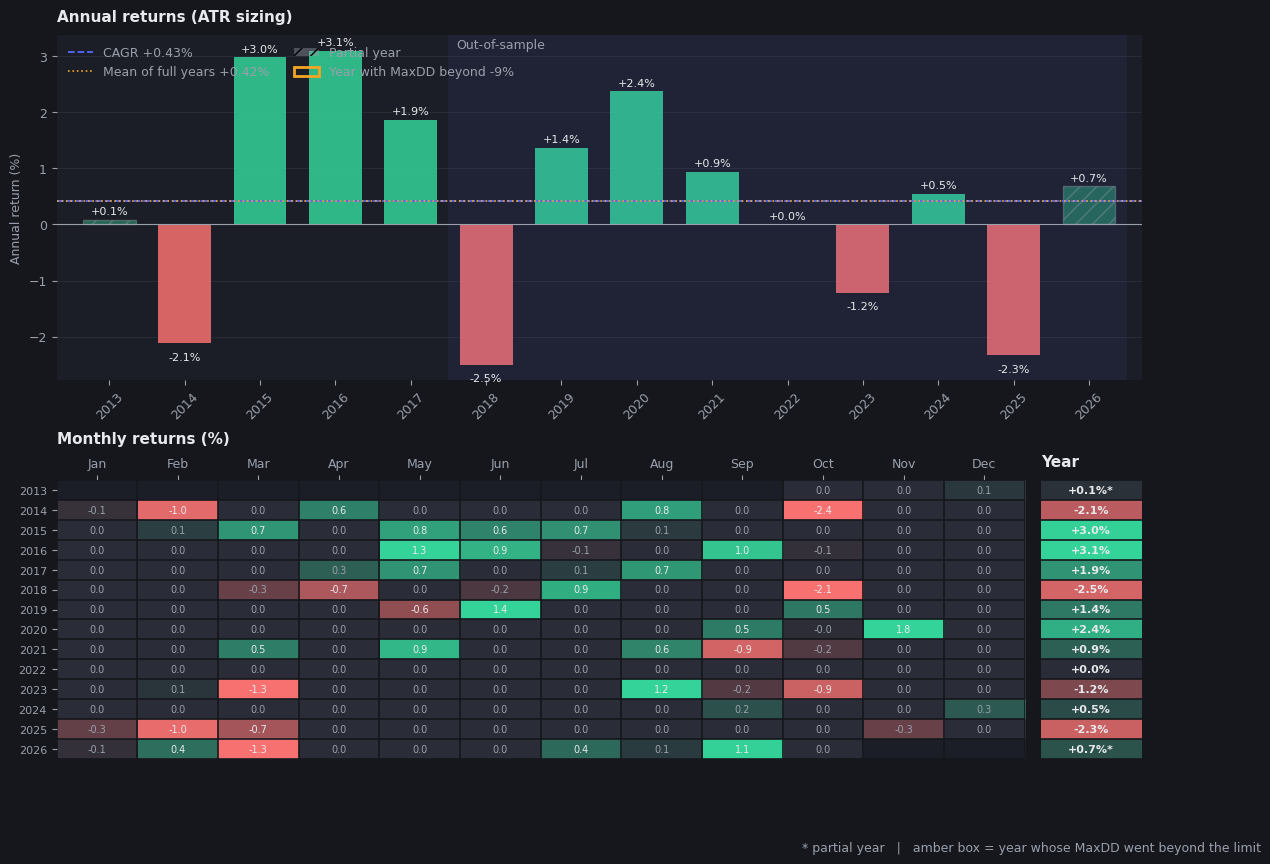

In [9]:
LIMIT = STOP_LIMIT
BG, PANEL, GRID, TXT, TXT2 = '#15171c', '#1b1e26', '#2a2d37', '#e8e9ec', '#9aa0ab'
GREEN, RED, AMBER, BLUE = '#34d399', '#f87171', '#f5a524', '#5468ff'
MONTHS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

ret_atr = eng.daily_returns(df, trades_all, sizing="atr").astype(float)
ret_cap = eng.daily_returns(df, trades_all, sizing="capital").astype(float)

def by_year(ret):
    g = ret.groupby(ret.index.year)
    return pd.DataFrame({
        "Return": g.apply(lambda x: (1 + x).prod() - 1),
        "MaxDD":  g.apply(lambda x: ((1 + x).cumprod() / (1 + x).cumprod().cummax() - 1).min()),
        "Days":   g.size(),
    })

def cagr(ret):
    yrs = (ret.index[-1] - ret.index[0]).days / 365.25
    return (1 + ret).prod() ** (1 / yrs) - 1

a, c = by_year(ret_atr), by_year(ret_cap)
first_y, last_y = ret_atr.index[0].year, ret_atr.index[-1].year
a["Partial"] = [(y in (first_y, last_y)) and d < 0.9*252 for y, d in zip(a.index, a["Days"])]

tbl = pd.DataFrame({
    "ATR return": a["Return"], "ATR MaxDD": a["MaxDD"],
    "Capital return": c["Return"], "Days": a["Days"],
    "Note": np.where(a["Partial"], "partial year", ""),
    "Breaches limit": np.where(a["MaxDD"] <= -LIMIT, "YES", ""),
})
tbl.index.name = "Year"

full = a[~a["Partial"]]
summary = pd.DataFrame({
    "ATR (live robot)": {
        "CAGR (whole period)":        cagr(ret_atr),
        "Mean annual (full years)":   full["Return"].mean(),
        "Median annual (full years)": full["Return"].median(),
        "Best year":                  f"{full['Return'].idxmax()}  {full['Return'].max():+.2%}",
        "Worst year":                 f"{full['Return'].idxmin()}  {full['Return'].min():+.2%}",
        "Positive years":             f"{(full['Return'] > 0).sum()} / {len(full)}  ({(full['Return']>0).mean():.0%})",
        "Years breaching the limit":  int((a['MaxDD'] <= -LIMIT).sum()),
    },
    "100% Capital": {
        "CAGR (whole period)":        cagr(ret_cap),
        "Mean annual (full years)":   c.loc[full.index, "Return"].mean(),
        "Median annual (full years)": c.loc[full.index, "Return"].median(),
        "Best year":                  f"{c.loc[full.index,'Return'].idxmax()}  {c.loc[full.index,'Return'].max():+.2%}",
        "Worst year":                 f"{c.loc[full.index,'Return'].idxmin()}  {c.loc[full.index,'Return'].min():+.2%}",
        "Positive years":             f"{(c.loc[full.index,'Return']>0).sum()} / {len(full)}  ({(c.loc[full.index,'Return']>0).mean():.0%})",
        "Years breaching the limit":  "-",
    },
})

print("=" * 78)
print(f"ANNUAL RETURNS | {ret_atr.index[0]:%Y-%m-%d} -> {ret_atr.index[-1]:%Y-%m-%d}")
print("=" * 78)
display(summary.style.format(lambda v: f"{v:+.2%}" if isinstance(v, (float, np.floating)) else v))
display(tbl.style
        .format({"ATR return":"{:+.2%}", "ATR MaxDD":"{:.2%}", "Capital return":"{:+.2%}"})
        .map(lambda v: f"color: {GREEN}" if v > 0 else f"color: {RED}", subset=["ATR return","Capital return"]))

# Monthly heatmap
def style(ax, title, ylabel=None):
    ax.set_facecolor(PANEL)
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(colors=TXT2, labelsize=9)
    ax.set_title(title, color=TXT, fontweight='bold', fontsize=11, loc='left', pad=10)
    if ylabel: ax.set_ylabel(ylabel, color=TXT2, fontsize=9)

monthly = ((1 + ret_atr).groupby([ret_atr.index.year, ret_atr.index.month]).prod() - 1).unstack()
monthly = monthly.reindex(columns=range(1, 13)) * 100
n_years = len(monthly)

fig = plt.figure(figsize=(14, 5.2 + 0.30 * n_years), facecolor=BG)
gs = GridSpec(2, 2, height_ratios=[5.2, 0.30 * n_years], width_ratios=[12, 1.25],
              hspace=0.32, wspace=0.03, figure=fig)

ax = fig.add_subplot(gs[0, :])
style(ax, 'Annual returns (ATR sizing)', 'Annual return (%)')
ax.grid(True, axis='y', color=GRID, linewidth=0.8, alpha=0.9); ax.set_axisbelow(True)

yrs = a.index.values
vals = a["Return"].values * 100
bars = ax.bar(yrs, vals, color=[GREEN if v > 0 else RED for v in vals], alpha=0.85, width=0.7)
for b, (_, row) in zip(bars, a.iterrows()):
    if row["Partial"]:
        b.set_alpha(0.4); b.set_hatch('//'); b.set_edgecolor(TXT2)
    if row["MaxDD"] <= -LIMIT:
        b.set_edgecolor(AMBER); b.set_linewidth(2.0)
    v = row["Return"] * 100
    ax.annotate(f"{v:+.1f}%", (b.get_x() + b.get_width() / 2, v), xytext=(0, 4 if v >= 0 else -12),
                textcoords='offset points', ha='center', color=TXT, fontsize=8)

ax.axhline(0, color=TXT2, lw=0.8)
ax.axhline(cagr(ret_atr) * 100, color=BLUE, ls='--', lw=1.3)
ax.axhline(full["Return"].mean() * 100, color=AMBER, ls=':', lw=1.2)
ax.set_xticks(yrs); ax.set_xticklabels(yrs, rotation=45, color=TXT2, fontsize=9)
ax.set_xlim(yrs.min() - 0.7, yrs.max() + 0.7)
try:
    ax.axvspan(oos_start.year - 0.5, last_y + 0.5, color=BLUE, alpha=0.07, lw=0)
    ax.text(oos_start.year - 0.4, ax.get_ylim()[1] * 0.93, "Out-of-sample", color=TXT2, fontsize=9)
except NameError:
    pass
ax.legend(handles=[
    Line2D([0], [0], color=BLUE, ls='--', lw=1.3, label=f"CAGR {cagr(ret_atr):+.2%}"),
    Line2D([0], [0], color=AMBER, ls=':', lw=1.2, label=f"Mean of full years {full['Return'].mean():+.2%}"),
    Patch(facecolor=TXT2, alpha=0.4, hatch='//', label='Partial year'),
    Patch(facecolor='none', edgecolor=AMBER, lw=2, label=f"Year with MaxDD beyond -{LIMIT:.0%}"),
], frameon=False, labelcolor=TXT2, fontsize=9, loc='upper left', ncol=2)

cmap = LinearSegmentedColormap.from_list('rg', [RED, '#2a2d37', GREEN]); cmap.set_bad(PANEL)
vmax = max(float(np.nanpercentile(np.abs(monthly.values), 95)), 0.5)

axh = fig.add_subplot(gs[1, 0])
style(axh, 'Monthly returns (%)')
axh.imshow(np.ma.masked_invalid(monthly.values), cmap=cmap, vmin=-vmax, vmax=vmax, aspect='auto')
axh.set_xticks(range(12)); axh.set_xticklabels(MONTHS, color=TXT2, fontsize=9)
axh.set_yticks(range(n_years)); axh.set_yticklabels(monthly.index, color=TXT2, fontsize=8)
axh.xaxis.tick_top()
axh.set_xticks(np.arange(-0.5, 12, 1), minor=True); axh.set_yticks(np.arange(-0.5, n_years, 1), minor=True)
axh.grid(which='minor', color=BG, linewidth=1.2); axh.tick_params(which='minor', length=0)
for i in range(n_years):
    for j in range(12):
        v = monthly.values[i, j]
        if not np.isnan(v):
            axh.text(j, i, f"{v:.1f}", ha='center', va='center', fontsize=7,
                     color=TXT if abs(v) > vmax * 0.35 else TXT2)

axy = fig.add_subplot(gs[1, 1])
style(axy, 'Year')
yv = (a["Return"].values * 100).reshape(-1, 1)
vmax_y = max(float(np.nanpercentile(np.abs(yv), 95)), 1.0)
axy.imshow(yv, cmap=cmap, vmin=-vmax_y, vmax=vmax_y, aspect='auto')
axy.set_xticks([]); axy.set_yticks([])
axy.set_yticks(np.arange(-0.5, n_years, 1), minor=True)
axy.grid(which='minor', axis='y', color=BG, linewidth=1.2); axy.tick_params(which='minor', length=0)
for i, (_, row) in enumerate(a.iterrows()):
    axy.text(0, i, f"{row['Return'] * 100:+.1f}%{'*' if row['Partial'] else ''}", ha='center', va='center',
             fontsize=8, fontweight='bold', color=TXT)
    if row["MaxDD"] <= -LIMIT:
        axy.add_patch(Rectangle((-0.5, i - 0.5), 1, 1, fill=False, ec=AMBER, lw=1.8))
fig.text(0.985, 0.012, "* partial year   |   amber box = year whose MaxDD went beyond the limit",
         color=TXT2, fontsize=9, ha='right')
plt.show()

## 4.5b · HARD RISK LIMIT CHECK

In [10]:
LIMIT      = STOP_LIMIT
R0         = 0.01
STAGE_DAYS = 252
P_MAX      = 0.05
N_SIM, BLOCK, SEED = 10_000, 20, 42
R_GRID     = [0.002,0.003,0.004,0.005,0.006,0.007,0.008,0.009,0.010]
GATE       = "stage"

ret0 = eng.daily_returns(df, trades_all, sizing="atr").astype(float)

def underwater(ret):
    eq = (1 + ret).cumprod(); return eq, eq / eq.cummax() - 1

def stage_losses(ret, window):
    w = sliding_window_view(ret.values, window)
    return np.cumprod(1 + w, axis=1).min(axis=1) - 1

rng = np.random.default_rng(SEED)
v = ret0.values
n_blocks = int(np.ceil(STAGE_DAYS / BLOCK))
idx = (rng.integers(0, len(v), size=(N_SIM, n_blocks))[:, :, None] + np.arange(BLOCK)) % len(v)
sim0 = v[idx.reshape(N_SIM, -1)[:, :STAGE_DAYS]]

rows, min_paths = [], {}
for r in sorted(set(R_GRID + [R0])):
    k = r / R0
    ret = ret0 * k
    _, dd = underwater(ret)
    sl = stage_losses(ret, STAGE_DAYS)
    cum = np.cumprod(1 + sim0 * k, axis=1)
    min_paths[r] = cum.min(axis=1) - 1
    mdd_sim = (cum / np.maximum.accumulate(cum, axis=1) - 1).min(axis=1)
    rows.append({"r": r, "Hist MDD": dd.min(), "Worst stage loss": sl.min(),
                 "Stages > limit": (sl <= -LIMIT).mean(),
                 "P(touch limit)": (min_paths[r] <= -LIMIT).mean(),
                 "MDD p95 (stage)": np.percentile(mdd_sim, 5)})
res = pd.DataFrame(rows).set_index("r")
res["OK"] = (res[GATE.replace('stage','Worst stage loss') if GATE=='stage' else 'Hist MDD'] >= -LIMIT) & (res["P(touch limit)"] <= P_MAX)
ok_r = res.index[res["OK"]]; r_max = ok_r.max() if len(ok_r) else None
cur = res.loc[R0]; RISK_OK = bool(cur["OK"])

print("=" * 78)
print(f"HARD RISK LIMIT CHECK | limit -{LIMIT:.0%} | stage {STAGE_DAYS}d | ATR sizing r0={R0:.2%}")
print("=" * 78)
display(res.rename(index=lambda x: f"{x:.2%}").style.format({c:"{:.2%}" for c in res.columns if c!="OK"}))
print(f"Verdict at r={R0:.2%}: {'PASS' if RISK_OK else 'FAIL'}   Max passing r: {'none' if r_max is None else f'{r_max:.2%}'}")

HARD RISK LIMIT CHECK | limit -9% | stage 252d | ATR sizing r0=1.00%


,Hist MDD,Worst stage loss,Stages > limit,P(touch limit),MDD p95 (stage),OK
r,,,,,,
0.20%,-1.30%,-0.78%,0.00%,0.00%,-0.75%,True
0.30%,-1.94%,-1.18%,0.00%,0.00%,-1.12%,True
0.40%,-2.58%,-1.56%,0.00%,0.00%,-1.49%,True
0.50%,-3.22%,-1.95%,0.00%,0.00%,-1.86%,True
0.60%,-3.86%,-2.34%,0.00%,0.00%,-2.23%,True
0.70%,-4.49%,-2.73%,0.00%,0.00%,-2.60%,True
0.80%,-5.12%,-3.11%,0.00%,0.00%,-2.97%,True
0.90%,-5.75%,-3.49%,0.00%,0.00%,-3.33%,True
1.00%,-6.37%,-3.88%,0.00%,0.00%,-3.70%,True


Verdict at r=1.00%: PASS   Max passing r: 1.00%


## 5. SANITY CHECKS & VERIFICATION

In [11]:
print("=" * 70); print("SANITY CHECKS & REPRODUCIBILITY"); print("=" * 70)

for idx_, row in trades_all.iterrows():
    signal_time = df.index[row['i_ent'] - 1]
    entry_time  = row['entry_time']
    assert entry_time > signal_time, f"Lookahead at trade {idx_}!"
    assert df.index[int(row['i_ent'])] == entry_time, f"i_ent misaligned at trade {idx_}!"
    assert df.index[int(row['i_sal'])] == row['exit_time'], f"i_sal misaligned at trade {idx_}!"
    exp_entry = df.loc[entry_time, 'open'] * (1.0 + SLIP)
    assert np.isclose(row['entry_price'], exp_entry, atol=1e-4), f"Entry price mismatch at {idx_}!"
    if row['reason'] != 'open_at_end':
        exp_stop = row['entry_price'] - ATR_STOP_MULT * df.loc[signal_time, 'atr14']
        assert np.isclose(row['stop_price'], exp_stop, rtol=1e-4), \
            f"Stop mismatch at trade {idx_}: {row['stop_price']} vs {exp_stop}"
print(f"Sanity Check 1: PASSED. Zero lookahead across {len(trades_all)} trades; stop_price consistent.")

trades_all['year'] = pd.to_datetime(trades_all['entry_time']).dt.year
tpy = trades_all.groupby('year').size()
print(f"\nTrades/year: mean {tpy.mean():.1f}, min {tpy.min()} ({tpy.idxmin()}), max {tpy.max()} ({tpy.idxmax()})")

if len(hard_stops):
    stop_loss_pct = ((hard_stops['exit_price'] / hard_stops['entry_price']) - 1).mean()
    print(f"\nAvg hard-stop loss per trade: {stop_loss_pct*100:.2f}% (bounded by {ATR_STOP_MULT}x ATR)")
    print(f"Hard stop rate: {len(hard_stops)/len(trades_all)*100:.1f}% (remaining exits: target/time)")

SANITY CHECKS & REPRODUCIBILITY
Sanity Check 1: PASSED. Zero lookahead across 56 trades; stop_price consistent.

Trades/year: mean 4.3, min 1 (2013), max 7 (2014)

Avg hard-stop loss per trade: -2.49% (bounded by 2.0x ATR)
Hard stop rate: 28.6% (remaining exits: target/time)


## 6. REFERENCE VARIANT · BBMR vs CLASSIC BB

FULL BBMR vs CLASSIC BB (same BB, same stop, same exits — filters vary)


,Variant,Trades,Win Rate,Profit Factor,Expectancy,Avg Bars,Sharpe,MaxDD
0,"Full BBMR (ADX<25.0, reject>=0.5)",56,66.1%,1.222,0.160%,4.0,0.25,-13.77%
1,Classic BB (no filters),110,55.5%,0.958,-0.044%,4.0,0.31,-19.47%


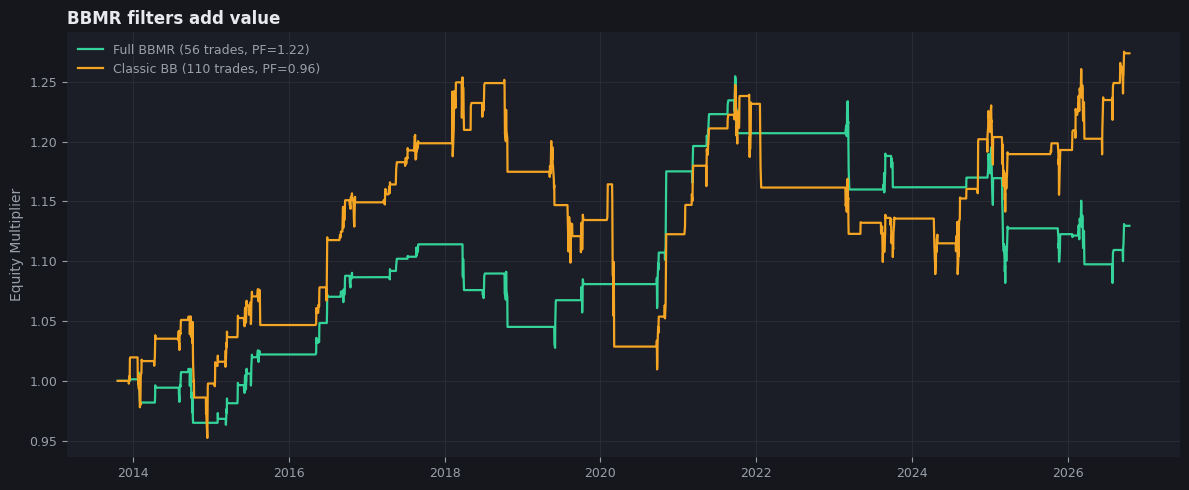

In [12]:
df_classic = eng.prepare(df_raw, sma_len=SMA_LEN, bb_len=BB_LEN, bb_std=BB_STD)
df_classic = df_classic[df_classic.index >= df.index[0]]
trades_classic = eng.run_bbmr_backtest(
    df_classic,
    bb_len=BB_LEN, bb_std=BB_STD, adx_thr=100.0, sma_len=SMA_LEN,
    rejection_ratio=0.0, max_bars=MAX_BARS, atr_stop_mult=ATR_STOP_MULT,
    slip_bps_per_side=SLIP_BPS,
)

m_tis = compute_metrics(trades_all, 1.0, 0.0)
m_con = compute_metrics(trades_classic, 1.0, 0.0)
ret_tis = eng.daily_returns(df, trades_all, "capital")
ret_con = eng.daily_returns(df_classic, trades_classic, "capital")
eq_tis = (1 + ret_tis).cumprod(); eq_con = (1 + ret_con).cumprod()

comp = pd.DataFrame([
    {'Variant': f"Full BBMR (ADX<{ADX_THR}, reject>={REJECTION_RATIO})",
     'Trades': m_tis['num_trades'], 'Win Rate': f"{m_tis['win_rate']:.1f}%",
     'Profit Factor': f"{m_tis['profit_factor']:.3f}", 'Expectancy': f"{m_tis['expectancy']:.3f}%",
     'Avg Bars': f"{trades_all['bars'].mean():.1f}",
     'Sharpe': f"{sharpe_ratio(ret_tis):.2f}", 'MaxDD': f"{max_drawdown(eq_tis)*100:.2f}%"},
    {'Variant': "Classic BB (no filters)",
     'Trades': m_con['num_trades'], 'Win Rate': f"{m_con['win_rate']:.1f}%",
     'Profit Factor': f"{m_con['profit_factor']:.3f}", 'Expectancy': f"{m_con['expectancy']:.3f}%",
     'Avg Bars': f"{trades_classic['bars'].mean():.1f}",
     'Sharpe': f"{sharpe_ratio(ret_con):.2f}", 'MaxDD': f"{max_drawdown(eq_con)*100:.2f}%"},
])
print("=" * 80); print("FULL BBMR vs CLASSIC BB (same BB, same stop, same exits — filters vary)"); print("=" * 80)
display(comp)

fig, ax = plt.subplots(figsize=(12, 5), facecolor='#15171c')
ax.set_facecolor('#1b1e26'); ax.grid(True, color='#2a2d37', linewidth=0.8, alpha=0.9)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(colors='#9aa0ab', labelsize=9)
ax.plot(df.index, eq_tis, color='#34d399', lw=1.6, label=f"Full BBMR ({m_tis['num_trades']} trades, PF={m_tis['profit_factor']:.2f})")
ax.plot(df_classic.index, eq_con, color='#f5a524', lw=1.6, label=f"Classic BB ({m_con['num_trades']} trades, PF={m_con['profit_factor']:.2f})")
ax.set_title('BBMR filters add value', color='#e8e9ec', fontweight='bold', fontsize=12, loc='left')
ax.set_ylabel('Equity Multiplier', color='#9aa0ab'); ax.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9, loc='upper left')
plt.tight_layout(); plt.show()

## 7. SUMMARY & METRICS

In [13]:
m_all, m_is, m_oos = compute_metrics(trades_all,1.0,0.0), compute_metrics(trades_is,1.0,0.0), compute_metrics(trades_oos,1.0,0.0)
max_dd_atr = max_drawdown(eq_atr_all)*100
years = (df.index[-1] - df.index[0]).days/365.25
confirmed = m_all["profit_factor"] > 1.5 and m_all["win_rate"] > 55

print("=" * 80); print("7. SUMMARY OF HYPOTHESIS & NEXT STEPS"); print("=" * 80)
print(f"""
1. {"Hypothesis CONFIRMED" if confirmed else "Hypothesis NOT clearly confirmed"}: BB touch + ADX<{ADX_THR}
   + rejection bar in uptrend yields a {m_all['win_rate']:.1f}% win rate and PF={m_all['profit_factor']:.3f}
   over {years:.0f}+ years ({m_all['num_trades']} trades).

2. Hard stop bounding: {ATR_STOP_MULT}x ATR with {hard_stops.shape[0]} stops hit
   ({hard_stops.shape[0]/max(len(trades_all),1)*100:.1f}% of trades), max DD {max_dd_atr:.2f}%.

3. Repro: IS {len(trades_is)} trades PF={m_is['profit_factor']:.3f}; OOS {len(trades_oos)} trades PF={m_oos['profit_factor']:.3f}.

4. Next: 02_BBMR_Optimization.ipynb for parameter stability (adx_thr × bb_std plateau).
""")

# Metrics dict for validation gate
ret_series_atr = eng.daily_returns(df, trades_all, sizing="atr")
eq_series_atr  = (1.0 + ret_series_atr).cumprod()
metrics = {
    "sharpe": float(sharpe_ratio(ret_series_atr)),
    "max_drawdown": float(max_drawdown(eq_series_atr)),
    "num_trades": int(len(trades_all))
}
print(f"Sharpe: {metrics['sharpe']:.2f} | MaxDD: {metrics['max_drawdown']*100:.2f}% | Trades: {metrics['num_trades']}")

7. SUMMARY OF HYPOTHESIS & NEXT STEPS

1. Hypothesis NOT clearly confirmed: BB touch + ADX<25.0
   + rejection bar in uptrend yields a 66.1% win rate and PF=1.222
   over 13+ years (56 trades).

2. Hard stop bounding: 2.0x ATR with 16 stops hit
   (28.6% of trades), max DD -6.37%.

3. Repro: IS 27 trades PF=1.685; OOS 29 trades PF=1.041.

4. Next: 02_BBMR_Optimization.ipynb for parameter stability (adx_thr × bb_std plateau).

Sharpe: 0.24 | MaxDD: -6.37% | Trades: 56


## 8. SAVE RESULTS

In [14]:
save_json(cfg, "01_hypothesis.json", {
    "variant": cfg["id"], "ticker": TICKER, "params": cfg["params"],
    "oos_start": str(oos_start.date()),
    "all": {"n": int(len(trades_all)), "pf": float(m_all["profit_factor"]), "win_rate": float(m_all["win_rate"])},
    "is":  {"n": int(len(trades_is)),  "pf": float(m_is["profit_factor"])},
    "oos": {"n": int(len(trades_oos)), "pf": float(m_oos["profit_factor"])},
    "max_dd_atr_pct": float(max_dd_atr),
    "hard_stop_rate_pct": float(hard_stops.shape[0] / max(len(trades_all),1) * 100),
    "hypothesis_confirmed": bool(confirmed),
    "metrics": metrics,
})

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/notebooks/BBMR/runs/v1_us500/01_hypothesis.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/notebooks/BBMR/runs/v1_us500/01_hypothesis.json')

## 9. SIGNAL PARITY

In [15]:
BASE_VARIANT = None
if BASE_VARIANT:
    cb = load_variant(BASE_VARIANT)
    diff = {k: (cb["params"].get(k), cfg["params"].get(k))
            for k in set(cb["params"]) | set(cfg["params"])
            if cb["params"].get(k) != cfg["params"].get(k)}
    if diff:
        print("WARNING: base params differ from variant. Both runs use VARIANT params:")
        for k, (bv, vv) in sorted(diff.items()): print(f"  {k}: {bv} vs {vv}")
    rb = eng.load_data(cb["instrument"]["ticker"], start=DATA_START, source="yahoo")
    idx = rb.index.intersection(df_raw.index)
    b, v_ = rb.loc[idx], df_raw.loc[idx]
    db = eng.prepare(b, sma_len=SMA_LEN, bb_len=BB_LEN, bb_std=BB_STD)
    dv = eng.prepare(v_, sma_len=SMA_LEN, bb_len=BB_LEN, bb_std=BB_STD)
    kw = _bbmr_kwargs()
    tb = eng.run_bbmr_backtest(db, financing_bps_per_night=0.0, **kw)
    tv = eng.run_bbmr_backtest(dv, **kw)
    def match(a, c):
        a, c = np.asarray(a), np.asarray(c)
        return float(np.mean([np.abs(c - x).min() <= 1 for x in a])) if len(a) and len(c) else 0.0
    def col(t, name): return t[name].values if len(t) else np.array([])
    print(f"corr close: {b.close.pct_change().corr(v_.close.pct_change()):.4f}")
    print(f"trades base/variant: {len(tb)}/{len(tv)} | "
          f"entries match: {min(match(col(tv,'i_ent'), col(tb,'i_ent')), match(col(tb,'i_ent'), col(tv,'i_ent'))):.0%} | "
          f"exits match: {min(match(col(tv,'i_sal'), col(tb,'i_sal')), match(col(tb,'i_sal'), col(tv,'i_sal'))):.0%}")
else:
    print("BASE_VARIANT is None: nothing to compare.")

BASE_VARIANT is None: nothing to compare.
